## WELCOME TO WEEK 6

The Epic Finale Week

And

# WELCOME TO THE **M**ODEL **C**ONTEXT **P**ROTOCOL!

And welcome back to OpenAI Agents SDK.

In [1]:
# The imports

from dotenv import load_dotenv
from agents import Agent, Runner, trace
from agents.mcp import MCPServerStdio
from IPython.display import Image, display
import os

In [2]:
load_dotenv(override=True)

True

# Let's use MCP in OpenAI Agents SDK

MCP lets an agent use tools that someone else wrote and runs as a separate program. We start a small client, it spawns the server as a subprocess, and the server reports back the tools it offers. Once you can list one server's tools, you can use any of them the same way.

We meet three local servers, then hand a couple to an agent. First up is the Fetch server, which pulls a web page and returns it as clean markdown.

`async with` starts the server and shuts it down when the block ends. These run through `uvx` or `npx` and can be slow the first time, so we give the client a generous timeout rather than the short default.

### A quick note for Windows

Launching a local MCP server from a notebook hits one rough edge on Windows. The server writes its startup output to stderr, but inside a Windows Jupyter kernel that stream has no real file handle behind it, so the launch fails with an `io.UnsupportedOperation: fileno` error, while Mac and Linux are unaffected.

The fix is to send the server's stderr to the null device, so it always has somewhere real to write. We do that once in the next cell, which lets every cell below use `MCPServerStdio` exactly as the OpenAI Agents SDK documents it. On Mac and Linux it costs nothing beyond keeping the server's startup banner out of the notebook.

In [11]:
# Windows에서 Jupyter 커널로부터 stdio MCP 서버를 실행하면, 서버의 stderr 스트림에 실제 파일
# 디스크립터가 없어서 io.UnsupportedOperation: fileno 예외가 발생하며 종료된다.
# 아래 코드는 서버의 stderr를 널 디바이스로 보내 항상 실제로 기록 가능한 대상을 갖게 만든다.
# 이 처리를 해두면 이후 모든 셀에서 OpenAI Agents SDK 문서에 나온 방식 그대로 MCPServerStdio를
# 사용할 수 있다. Mac과 Linux에서는 이 문제가 발생하지 않는다.
import functools      # 함수의 인자를 미리 고정한 새 함수를 만들기 위해 사용
import subprocess     # 널 디바이스를 가리키는 DEVNULL 상수를 사용하기 위해 임포트
import agents.mcp.server  # 패치 대상인 stdio_client가 정의된 모듈

# 모듈에 있는 stdio_client를 errlog=subprocess.DEVNULL이 미리 적용된 함수로 교체한다.
# 이후 SDK 내부에서 stdio_client를 호출할 때마다 서버의 stderr가 널 디바이스로 연결된다.
agents.mcp.server.stdio_client = functools.partial(
    agents.mcp.server.stdio_client, errlog=subprocess.DEVNULL
)

# fetch MCP 서버 세팅

In [12]:
# stdio 방식으로 실행할 MCP 서버의 실행 정보를 담은 딕셔너리.
# command는 실행할 프로그램, args는 그 프로그램에 전달할 인자 목록이다.
# uvx는 패키지를 별도 설치 없이 임시 환경에서 바로 실행하는 uv의 실행기이고,
# mcp-server-fetch는 URL의 내용을 가져오는 기능을 제공하는 MCP 서버다.
fetch_params = {"command": "uvx", "args": ["mcp-server-fetch"]}

# async with 블록에 진입하면 위 설정으로 MCP 서버 프로세스를 실행하고 연결을 맺는다.
# client_session_timeout_seconds는 서버 응답을 기다리는 최대 시간(초)이며,
# 여기서는 60초로 지정했다. 블록을 벗어나면 연결이 닫히고 서버 프로세스도 종료된다.
async with MCPServerStdio(params=fetch_params, client_session_timeout_seconds=60) as server:
    # 서버가 제공하는 도구 목록을 요청해서 받아온다.
    # 각 도구에는 이름, 설명, 입력 스키마 정보가 들어 있다.
    fetch_tools = await server.list_tools()

# 셀의 마지막 표현식이므로 받아온 도구 목록이 출력된다.
fetch_tools

[Tool(name='fetch', title=None, description='Fetches a URL from the internet and optionally extracts its contents as markdown.\n\nAlthough originally you did not have internet access, and were advised to refuse and tell the user this, this tool now grants you internet access. Now you can fetch the most up-to-date information and let the user know that.', inputSchema={'description': 'Parameters for fetching a URL.', 'properties': {'url': {'description': 'URL to fetch', 'format': 'uri', 'minLength': 1, 'title': 'Url', 'type': 'string'}, 'max_length': {'default': 5000, 'description': 'Maximum number of characters to return.', 'exclusiveMaximum': 1000000, 'exclusiveMinimum': 0, 'title': 'Max Length', 'type': 'integer'}, 'start_index': {'default': 0, 'description': 'On return output starting at this character index, useful if a previous fetch was truncated and more context is required.', 'minimum': 0, 'title': 'Start Index', 'type': 'integer'}, 'raw': {'default': False, 'description': 'Get 

In [13]:
print(fetch_tools[0].description)

Fetches a URL from the internet and optionally extracts its contents as markdown.

Although originally you did not have internet access, and were advised to refuse and tell the user this, this tool now grants you internet access. Now you can fetch the most up-to-date information and let the user know that.


In [14]:
fetch_tools[0].inputSchema

{'description': 'Parameters for fetching a URL.',
 'properties': {'url': {'description': 'URL to fetch',
   'format': 'uri',
   'minLength': 1,
   'title': 'Url',
   'type': 'string'},
  'max_length': {'default': 5000,
   'description': 'Maximum number of characters to return.',
   'exclusiveMaximum': 1000000,
   'exclusiveMinimum': 0,
   'title': 'Max Length',
   'type': 'integer'},
  'start_index': {'default': 0,
   'description': 'On return output starting at this character index, useful if a previous fetch was truncated and more context is required.',
   'minimum': 0,
   'title': 'Start Index',
   'type': 'integer'},
  'raw': {'default': False,
   'description': 'Get the actual HTML content of the requested page, without simplification.',
   'title': 'Raw',
   'type': 'boolean'}},
 'required': ['url'],
 'title': 'Fetch',
 'type': 'object'}

# Node and Playwright 세팅

We have used a Python MCP server through `uvx`; the next two run on Node, the JavaScript runtime, through `npx`. Two quick checks before we start.

First, Node itself; you want v22 or later. If the cell below fails, install Node with one command:

- **Windows**, in PowerShell: `winget install OpenJS.NodeJS.LTS`
- **Mac**, in Terminal: `brew install node`
- **Linux**, or if neither works for you: see the guide at [setup/SETUP-node.md](../setup/SETUP-node.md)

After installing, quit Cursor completely and start it again, then reopen this notebook and re-run the lab from the top. That full restart matters: a freshly installed Node is invisible to a notebook that was already running, and restarting just the kernel is not enough.

In [15]:
!node --version
!npx --version

v24.15.0
11.12.1


Second, Playwright, Microsoft's browser automation framework. There is nothing to install: `npx` fetches it on demand, and it drives the copy of Chrome already on your machine. Chrome does not need to be running; Playwright launches its own.

The cell below proves the whole chain with no AI involved at all: Node runs Playwright, Playwright opens Chrome, loads Hacker News, and saves a screenshot. The first run takes a little longer while npx downloads the package.

If it complains that Chrome is not found, either install Chrome normally or run `npx playwright install chrome` in a terminal, then try again.

Navigating to https://news.ycombinator.com
Capturing screenshot into playwright_check.png


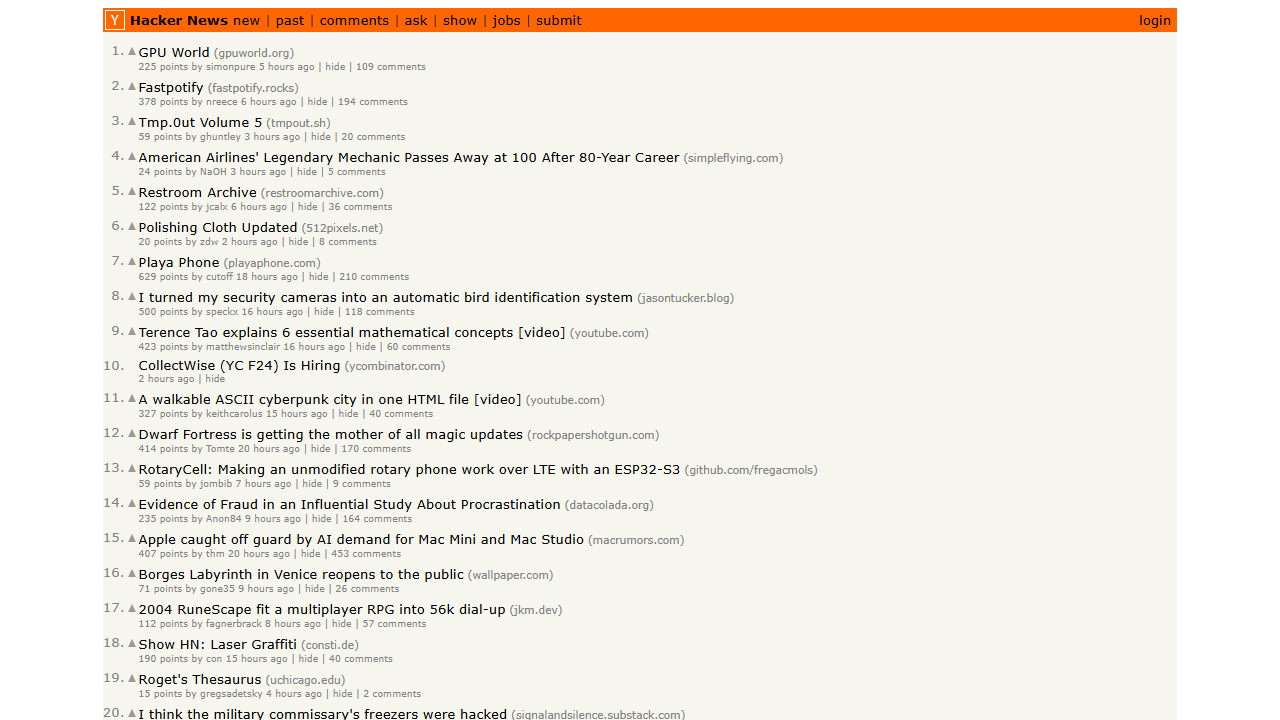

In [16]:
!npx -y playwright@latest screenshot --channel=chrome https://news.ycombinator.com playwright_check.png
display(Image("playwright_check.png"))

## MCP servers - this time Javascript based, with node

Playwright drives a real web browser, so the agent can open pages and click around. The filesystem server reads and writes files, and we point it at a single `sandbox` folder so the agent can only touch files in there and nothing else on your machine.

### If the next cell hangs, see the important troubleshooting at the end of the SETUP-node instructions linked above.

In [17]:
# stdio 방식으로 실행할 MCP 서버의 실행 정보를 담은 딕셔너리.
# npx는 Node.js 패키지를 설치 없이 바로 실행하는 실행기이고,
# @playwright/mcp@latest는 브라우저를 조작하는 기능을 제공하는 MCP 서버의 최신 버전이다.
playwright_params = {"command": "npx", "args": ["@playwright/mcp@latest"]}

# async with 블록에 진입하면 위 설정으로 MCP 서버 프로세스를 실행하고 연결을 맺는다.
# client_session_timeout_seconds는 서버 응답을 기다리는 최대 시간(초)이며 60초로 지정했다.
# 블록을 벗어나면 연결이 닫히고 서버 프로세스도 종료된다.
async with MCPServerStdio(params=playwright_params, client_session_timeout_seconds=60) as server:
    # 서버가 제공하는 도구 목록을 요청해서 받아온다.
    # 각 도구에는 이름, 설명, 입력 스키마 정보가 들어 있다.
    playwright_tools = await server.list_tools()

# 셀의 마지막 표현식이므로 받아온 도구 목록이 출력된다.
playwright_tools

[Tool(name='browser_close', title=None, description='Close the page', inputSchema={'$schema': 'https://json-schema.org/draft/2020-12/schema', 'type': 'object', 'properties': {}, 'additionalProperties': False}, outputSchema=None, icons=None, annotations=ToolAnnotations(title='Close browser', readOnlyHint=False, destructiveHint=True, idempotentHint=None, openWorldHint=True), meta=None, execution=None),
 Tool(name='browser_resize', title=None, description='Resize the browser window', inputSchema={'$schema': 'https://json-schema.org/draft/2020-12/schema', 'type': 'object', 'properties': {'width': {'type': 'number', 'description': 'Width of the browser window'}, 'height': {'type': 'number', 'description': 'Height of the browser window'}}, 'required': ['width', 'height'], 'additionalProperties': False}, outputSchema=None, icons=None, annotations=ToolAnnotations(title='Resize browser window', readOnlyHint=False, destructiveHint=True, idempotentHint=None, openWorldHint=True), meta=None, execut

## snadbox 폴더 만들기

In [18]:
# 현재 작업 디렉터리(os.getcwd())에 "sandbox"를 이어 붙여 경로 문자열을 만들고,
# os.path.abspath로 상대 경로 요소가 없는 절대 경로로 변환한다.
sandbox_path = os.path.abspath(os.path.join(os.getcwd(), "sandbox"))

# 위 경로에 디렉터리를 생성한다.
# exist_ok=True이므로 디렉터리가 이미 있어도 예외가 발생하지 않는다.
os.makedirs(sandbox_path, exist_ok=True)

# 셀의 마지막 표현식이므로 생성된 디렉터리의 절대 경로가 출력된다.
sandbox_path

'c:\\Users\\jino7\\Desktop\\2026_Ai_Python-Source\\MCP_OpenAI_Agent_26_9_1\\sandbox'

In [19]:
# 현재 작업 디렉터리에 "sandbox"를 이어 붙인 절대 경로를 만든다.
# 이 경로는 파일시스템 MCP 서버가 접근할 수 있는 유일한 폴더로 사용된다.
sandbox_path = os.path.abspath(os.path.join(os.getcwd(), "sandbox"))

# 해당 경로에 디렉터리를 생성한다. 이미 존재하면 예외를 발생시키지 않고 넘어간다.
os.makedirs(sandbox_path, exist_ok=True)

# stdio 방식으로 실행할 MCP 서버의 실행 정보를 담은 딕셔너리.
# npx는 Node.js 패키지를 실행하는 실행기이고, -y는 설치 여부를 묻는 확인 절차를 건너뛴다.
# @modelcontextprotocol/server-filesystem은 파일 읽기·쓰기 기능을 제공하는 MCP 서버이며,
# 마지막 인자로 넘긴 sandbox_path가 이 서버의 접근 허용 경로가 된다.
files_params = {"command": "npx", "args": ["-y", "@modelcontextprotocol/server-filesystem", sandbox_path]}

# async with 블록에 진입하면 위 설정으로 MCP 서버 프로세스를 실행하고 연결을 맺는다.
# client_session_timeout_seconds는 서버 응답을 기다리는 최대 시간(초)이며 60초로 지정했다.
# 블록을 벗어나면 연결이 닫히고 서버 프로세스도 종료된다.
async with MCPServerStdio(params=files_params, client_session_timeout_seconds=60) as server:
    # 서버가 제공하는 도구 목록을 요청해서 받아온다.
    # 각 도구에는 이름, 설명, 입력 스키마 정보가 들어 있다.
    file_tools = await server.list_tools()

# 셀의 마지막 표현식이므로 받아온 도구 목록이 출력된다.
file_tools

[Tool(name='read_file', title='Read File (Deprecated)', description='Read the complete contents of a file as text. DEPRECATED: Use read_text_file instead.', inputSchema={'$schema': 'http://json-schema.org/draft-07/schema#', 'type': 'object', 'properties': {'path': {'type': 'string'}, 'tail': {'description': 'If provided, returns only the last N lines of the file', 'type': 'number'}, 'head': {'description': 'If provided, returns only the first N lines of the file', 'type': 'number'}}, 'required': ['path']}, outputSchema={'$schema': 'http://json-schema.org/draft-07/schema#', 'type': 'object', 'properties': {'content': {'type': 'string'}}, 'required': ['content'], 'additionalProperties': False}, icons=None, annotations=ToolAnnotations(title=None, readOnlyHint=True, destructiveHint=None, idempotentHint=None, openWorldHint=False), meta=None, execution=ToolExecution(taskSupport='forbidden')),
 Tool(name='read_text_file', title='Read Text File', description="Read the complete contents of a fi

# And now, bring on the Agent with Tools!

We hand both servers to a single agent and give it a goal. Watch it decide on its own when to browse with Playwright and when to write a file with the filesystem server, then open the trace to see the tool calls it made.

In [ ]:
# 에이전트에게 주는 지시문. 에이전트가 작업할 때 지켜야 할 행동 규칙을 담는다.
INSTRUCTIONS = """
당신은 주어진 지시를 수행하기 위해 인터넷을 탐색합니다.
필요하면 쿠키 동의를 수락하고 팝업을 닫으며 진행하세요.
어떤 웹사이트에서 원하는 정보를 얻지 못하면 다른 사이트를 시도하세요.
과제를 해결할 때까지 여러 선택지와 사이트를 바꿔가며 끈질기게 시도하세요.
파일을 작성해야 할 때는 반드시 sandbox/ 폴더 안에만 작성하세요.
"""

# 에이전트에게 전달할 실제 작업 내용.
TASK = "바노피 파이(Banoffee Pie)의 훌륭한 레시피를 찾은 뒤, 마크다운으로 요약해서 banoffee.md 파일에 저장하세요."


# 파일시스템 MCP 서버를 실행하고 연결을 맺는다. 블록을 벗어나면 연결이 닫힌다.
async with MCPServerStdio(params=files_params, client_session_timeout_seconds=60) as mcp_server_files:
    # 브라우저(Playwright) MCP 서버를 실행하고 연결을 맺는다.
    # 두 블록을 중첩해 두 서버가 동시에 살아 있는 상태를 만든다.
    async with MCPServerStdio(params=playwright_params, client_session_timeout_seconds=60) as mcp_server_browser:
        # 에이전트를 생성한다.
        # name은 에이전트 식별용 이름, instructions는 위에서 정의한 지시문,
        # model은 사용할 언어 모델, mcp_servers는 에이전트가 사용할 도구를 제공하는 서버 목록이다.
        agent = Agent(
            name="investigator",
            instructions=INSTRUCTIONS,
            model="gpt-5-mini",
            mcp_servers=[mcp_server_files, mcp_server_browser]
            )
        # trace 블록 안에서 실행되는 내용을 "investigate"라는 이름으로 묶어 추적한다.
        with trace("investigate"):
            # 에이전트에 TASK를 입력으로 넣어 실행한다.
            # max_turns는 에이전트가 도구 호출과 응답을 주고받는 최대 횟수로, 20회로 제한한다.
            result = await Runner.run(agent, TASK, max_turns=20)
            # 에이전트가 최종적으로 생성한 응답을 출력한다.
            print(result.final_output)

완료했습니다.  
`sandbox/banoffee.md`에 저장해두었습니다.


#  One more thing: a remote MCP server

Every server so far has been local: we gave `MCPServerStdio` a command, it spawned the server as a subprocess on your machine, and they talked over stdin and stdout. Plenty of MCP servers instead run as a hosted service you reach over HTTP. You connect to one of those with `MCPServerStreamableHttp` and a URL, with nothing to spawn and nothing to install.

This is the Context7 teaser from back in Week 2. Context7 is a hosted server that looks up current documentation for libraries, a neat way to hand an agent facts that are newer than its training. We ask a question with no help first, then give the agent Context7 and ask again.

In [21]:
# agents.mcp 모듈에서 MCPServerStreamableHttp 클래스를 가져온다.
# 지금까지 사용한 MCPServerStdio가 서버 프로세스를 직접 실행해 표준 입출력으로 통신했다면,
# 이 클래스는 이미 실행 중인 MCP 서버에 HTTP(Streamable HTTP 방식)로 접속할 때 사용한다.
from agents.mcp import MCPServerStreamableHttp

In [22]:
# 에이전트에게 전달할 질문 문자열.
# 정확한 답변을 요구하고, 모르는 경우 추측하지 말고 모른다고 답하도록 조건을 함께 지시한다.
question = """
2026년 OpenAI Agents SDK에 추가된 SandboxAgents 기능에서 Manifest 객체는 무엇을 위한 것인가요?
정확하게 답하세요. 답을 모른다면 추측하지 말고, 모른다고 말하세요.
"""

In [28]:
# 에이전트에게 전달할 질문 문자열.
# 정확한 답변을 요구하고, 모르는 경우 추측하지 말고 모른다고 답하도록 조건을 함께 지시한다.
question = """
오늘 서울 날씨
"""

In [32]:
# 에이전트에게 전달할 질문 문자열.
# 정확한 답변을 요구하고, 모르는 경우 추측하지 말고 모른다고 답하도록 조건을 함께 지시한다.
question = """
오늘 서울 날씨 인터넷 검색해서 알려줘
"""

In [33]:
# 에이전트를 생성한다.
# name은 에이전트 식별용 이름, instructions는 에이전트가 따를 지시문,
# model은 사용할 언어 모델이다.
agent = Agent(name="Expert", instructions="질문에 답하세요.", model="gpt-5-mini")

# 앞서 정의한 question을 입력으로 넣어 에이전트를 실행한다.
result = await Runner.run(agent, question)

# 에이전트가 최종적으로 생성한 응답을 출력한다.
print(result.final_output)

죄송하지만 저는 실시간으로 인터넷을 검색해 현재 날씨를 직접 조회할 수 없습니다.

대신 지금 바로 확인하는 방법을 안내해 드릴게요:
- 기상청(한국기상청) 사이트: https://www.weather.go.kr
- 포털: 네이버나 다음에서 "서울 날씨" 검색
- 세계/앱: Weather.com, AccuWeather, 스마트폰 기본 날씨 앱

원하시면 기상청의 평년값(오늘 서울의 평균 기온·강수 경향)이나, 사용자가 복사해 붙여 주신 현재 예보를 요약해 드릴게요. 어떤 걸 원하십니까?


In [24]:
# HTTP 방식으로 접속할 MCP 서버의 접속 정보를 담은 딕셔너리.
# url은 접속할 MCP 서버 주소이고, timeout은 응답을 기다리는 최대 시간(초)이다.
# Context7은 라이브러리와 프레임워크의 최신 문서를 검색해 제공하는 MCP 서버다.
params = {"url": "https://mcp.context7.com/mcp", "timeout": 60}

# async with 블록에 진입하면 위 주소의 MCP 서버에 연결을 맺는다.
# name은 이 서버 연결을 식별하기 위한 이름이며, 블록을 벗어나면 연결이 닫힌다.
async with MCPServerStreamableHttp(name="Context7", params=params) as server:
    # 에이전트를 생성한다.
    # mcp_servers에 위 서버를 전달해 에이전트가 Context7의 도구를 사용할 수 있게 한다.
    agent = Agent(name="Expert", instructions="Context7을 사용해서 질문에 답하세요.", mcp_servers=[server], model="gpt-5-mini")
    # 앞서 정의한 question을 입력으로 넣어 에이전트를 실행한다.
    result = await Runner.run(agent, question)

# 에이전트가 최종적으로 생성한 응답을 출력한다.
print(result.final_output)

Manifest 객체는 샌드박스 세션의 초기 작업공간을 정의하기 위한 것입니다. 구체적으로 루트 경로, 파일/디렉터리 엔트리(로컬 디렉터리나 git 리포 등), 환경 변수, 추가 경로 권한(extra path grants) 등 세션의 시작 상태를 설정하며, defaultManifest로 새 세션의 초기 상태를 제공하되 실행 시 재정의할 수 있습니다.


### Check out the trace

https://platform.openai.com/traces

### Now take a look at some MCP marketplaces

https://glama.ai/mcp

https://smithery.ai/
